<a href="https://colab.research.google.com/github/Hamdi-Jarban/--/blob/main/ThaiCRNN_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ThaiCRNN — نسخة جاهزة للتشغيل على Google Colab

هذا الدفتر مبني على هيكل [`GitYCC/crnn-pytorch`](https://github.com/GitYCC/crnn-pytorch/tree/master/src)،
مُعاد تنظيمه بالكامل ليعمل مباشرة داخل Colab مع معالجة صريحة لمشاكل تعارض المكتبات
الشائعة (خصوصاً `torch`/`torchvision` المثبَّتين مسبقاً، و`pythainlp` ومتطلباتها).

## 1) فحص البيئة (Torch / CUDA)

**لماذا هذه الخطوة أولاً؟** Colab يأتي مع نسخة `torch` مُثبَّتة مسبقاً ومُطابقة تماماً
لإصدار الـ CUDA driver الخاص بالجهاز الافتراضي المخصَّص لك. إعادة تثبيت `torch` يدوياً
(كما يفعل كثير من الدروس القديمة عبر `pip install torch==1.x`) هو **السبب الأشيع لأخطاء
`CUDA error` أو `undefined symbol`** في Colab. لذلك هذا الدفتر **لا يعيد تثبيت torch إطلاقاً**
ويستخدم فقط ما هو مثبَّت مسبقاً.


In [ ]:
import sys, torch, platform

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("تنبيه: لا يوجد GPU مفعّل. اذهب إلى Runtime > Change runtime type > GPU لتسريع التدريب.")

Python: 3.12.13
Platform: Linux-6.6.122+-x86_64-with-glibc2.35
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## 2) تثبيت المكتبات الإضافية فقط (pythainlp)

نُثبّت **فقط** ما هو غير موجود مسبقاً في Colab. لا نلمس `torch`, `torchvision`, `numpy`,
`pillow` لأنها مثبَّتة مسبقاً بإصدارات متوافقة مع بعضها البعض، وإعادة تثبيتها يدوياً
قد يكسر هذا التوافق (تعارض إصدارات numpy الشائع بين Colab وبعض حزم pip القديمة).

**إن ظهرت رسالة `pip's dependency resolver` تحذيرية بعد التثبيت — هذا طبيعي ولا يمنع
عمل الكود**، لكن إن ظهر خطأ فعلي (Import error) بعد التثبيت، نفّذ:
`Runtime > Restart session` ثم أعد تشغيل الخلايا من البداية (بدون إعادة تثبيت torch).

In [ ]:
# تثبيت pythainlp فقط — لا يعتمد على torch إطلاقاً، آمن للتثبيت في أي وقت
!pip install --quiet pythainlp

import pythainlp
print("pythainlp:", pythainlp.__version__)
print("عدد الحروف الساكنة التايلاندية:", len(pythainlp.thai_consonants))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.8/19.8 MB 45.9 MB/s eta 0:00:00


## 3) (اختياري) ربط Google Drive

مفيد لحفظ نقاط التحقق (checkpoints) بشكل دائم بدلاً من فقدانها عند انتهاء جلسة Colab.
تجاهل هذه الخلية إذا كنت تريد العمل محلياً داخل جلسة Colab المؤقتة فقط.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# غيّر هذا المسار إلى مجلد داخل Drive الخاص بك إذا فعّلت الربط أعلاه
DRIVE_CHECKPOINT_DIR = '/content/drive/MyDrive/thai_crnn_checkpoints'
import os
os.makedirs(DRIVE_CHECKPOINT_DIR, exist_ok=True)
print("سيتم حفظ نقاط التحقق في:", DRIVE_CHECKPOINT_DIR)

## 4) إنشاء هيكل المشروع

سنستخدم `%%writefile` لكتابة كل ملف من ملفات المشروع (`thai_alphabet.py`, `config.py`,
`dataset.py`, `model.py`, `ctc_decoder.py`) على قرص Colab المؤقت، ثم نستوردها كوحدات
بايثون عادية. هذا يحافظ على نفس التنظيم المعياري (modular) لهيكل GitYCC الأصلي
بدلاً من دمج كل شيء في خلية واحدة ضخمة يصعب صيانتها.

In [ ]:
import os

PROJECT_DIR = '/content/thai_crnn'
os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/checkpoints', exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/data/images', exist_ok=True)

os.chdir(PROJECT_DIR)
print("مجلد العمل الحالي:", os.getcwd())

مجلد العمل الحالي: /content/thai_crnn


In [ ]:
%%writefile thai_alphabet.py
"""
thai_alphabet.py
-----------------
يبني قائمة الرموز (character set) الكاملة التي سيتعرف عليها نموذج CRNN.
يحاول أولاً استخدام PyThaiNLP (الأدق والأشمل)، وإن لم تكن مثبّتة يستخدم قائمة
يدوية مبنية على نطاقات يونيكود التايلاندية الرسمية (U+0E01 - U+0E5B).
"""

try:
    import pythainlp
    _HAS_PYTHAINLP = True
except ImportError:
    _HAS_PYTHAINLP = False


def _manual_thai_charset():
    consonants = [chr(c) for c in range(0x0E01, 0x0E2F + 1)]
    vowels_signs = [chr(c) for c in range(0x0E30, 0x0E3A + 1)]
    lead_vowels = [chr(c) for c in range(0x0E40, 0x0E44 + 1)]
    tone_marks = [chr(c) for c in range(0x0E48, 0x0E4B + 1)]
    other_signs = [chr(0x0E45), chr(0x0E46), chr(0x0E4C), chr(0x0E4D), chr(0x0E4E)]
    thai_digits = [chr(c) for c in range(0x0E50, 0x0E59 + 1)]
    return consonants + vowels_signs + lead_vowels + tone_marks + other_signs + thai_digits


def build_charset(include_latin_digits=True, include_basic_punct=True):
    if _HAS_PYTHAINLP:
        chars = list(pythainlp.thai_consonants)
        chars += list(pythainlp.thai_vowels)
        chars += (list(pythainlp.thai_lead_vowels)
                  if hasattr(pythainlp, "thai_lead_vowels")
                  else [chr(c) for c in range(0x0E40, 0x0E44 + 1)])
        chars += (list(pythainlp.thai_tonemarks)
                  if hasattr(pythainlp, "thai_tonemarks")
                  else [chr(c) for c in range(0x0E48, 0x0E4B + 1)])
        chars += list(pythainlp.thai_digits)
        chars += (list(pythainlp.thai_signs)
                  if hasattr(pythainlp, "thai_signs")
                  else [chr(0x0E45), chr(0x0E46), chr(0x0E4C), chr(0x0E4D), chr(0x0E4E)])
    else:
        chars = _manual_thai_charset()

    if include_latin_digits:
        chars += list("0123456789")
    if include_basic_punct:
        chars += list(" .,()-/%")

    seen = set()
    ordered_unique = []
    for c in chars:
        if c not in seen:
            seen.add(c)
            ordered_unique.append(c)
    return ordered_unique


THAI_CHARS = build_charset()
BLANK_IDX = 0
CHAR_TO_IDX = {c: i + 1 for i, c in enumerate(THAI_CHARS)}
IDX_TO_CHAR = {i + 1: c for i, c in enumerate(THAI_CHARS)}
NUM_CLASSES = len(THAI_CHARS) + 1

if __name__ == "__main__":
    print(f"عدد الرموز (بدون blank): {len(THAI_CHARS)}")
    print(f"عدد الأصناف الكلي (مع blank): {NUM_CLASSES}")

Overwriting thai_alphabet.py


In [ ]:
%%writefile config.py
"""config.py — إعدادات ThaiCRNN"""

from thai_alphabet import THAI_CHARS, NUM_CLASSES, BLANK_IDX

CHARS = THAI_CHARS
NUM_CLASS = NUM_CLASSES
BLANK_LABEL = BLANK_IDX

IMG_HEIGHT = 48
IMG_WIDTH = 280
IMG_CHANNEL = 1

assert IMG_HEIGHT % 16 == 0, "يجب أن يكون IMG_HEIGHT من مضاعفات 16"
assert IMG_WIDTH % 4 == 0, "يجب أن يكون IMG_WIDTH من مضاعفات 4"

SEQ_LENGTH = IMG_WIDTH // 4 - 1

MAP_TO_SEQ_HIDDEN = 64
RNN_HIDDEN = 256
LEAKY_RELU = False
DROPOUT = 0.2  # جديد: تنظيم إضافي لتقليل الإفراط في التخصيص (overfitting)

BATCH_SIZE = 32
LEARNING_RATE = 0.0005
EPOCHS = 100
CPU_WORKERS = 0   # 0 في Colab تحديداً: يتفادى خطأ AssertionError الشهير في تنظيف
                  # عمليات DataLoader الفرعية (ipykernel + fork)، وهو غير ضروري
                  # أصلاً لمجموعات بيانات صغيرة/متوسطة الحجم
REVERSE_LABEL = False

TRAIN_LABELS_CSV = "data/train_labels.csv"
VALID_LABELS_CSV = "data/valid_labels.csv"
IMAGES_ROOT_DIR = "data"   # تم تصحيحه: كان "data/images" مما يسبب تكرار المجلد
                             # لأن مسار الصورة المخزَّن في CSV يبدأ أصلاً بـ "images/"

CHECKPOINTS_DIR = "checkpoints/"
SAVE_INTERVAL = 500

Writing config.py


In [ ]:
%%writefile dataset.py
"""dataset.py — تحميل بيانات OCR تايلاندية بصيغة CSV (image_path,text) UTF-8"""

import csv
import os

import torch
from torch.utils.data import Dataset
from PIL import Image
import torchvision.transforms as transforms

from thai_alphabet import CHAR_TO_IDX
import config


def text_to_indices(text):
    indices = []
    for ch in text:
        if ch in CHAR_TO_IDX:
            indices.append(CHAR_TO_IDX[ch])
        else:
            print(f"تحذير: الرمز \'{ch}\' (U+{ord(ch):04X}) غير موجود في الأبجدية، سيُتجاهل.")
    return indices


class ThaiOCRDataset(Dataset):
    def __init__(self, labels_csv_path, images_root_dir,
                 img_height=config.IMG_HEIGHT, img_width=config.IMG_WIDTH):
        self.images_root_dir = images_root_dir
        self.img_height = img_height
        self.img_width = img_width
        self.samples = self._load_labels(labels_csv_path)

    @staticmethod
    def _load_labels(labels_csv_path):
        samples = []
        with open(labels_csv_path, mode="r", encoding="utf-8", newline="") as f:
            reader = csv.reader(f)
            for row in reader:
                if len(row) < 2:
                    continue
                samples.append((row[0], row[1]))
        return samples

    def __len__(self):
        return len(self.samples)

    def _load_and_resize_image(self, full_path):
        image = Image.open(full_path).convert("L")
        w, h = image.size
        target_h = self.img_height
        scale = target_h / float(h)
        new_w = min(int(w * scale), self.img_width)
        image = image.resize((max(new_w, 1), target_h), Image.BILINEAR)

        padded = Image.new("L", (self.img_width, target_h), color=255)
        padded.paste(image, (0, 0))
        return padded

    def __getitem__(self, idx):
        image_path, text = self.samples[idx]
        full_path = os.path.join(self.images_root_dir, image_path)

        image = self._load_and_resize_image(full_path)
        image = transforms.ToTensor()(image)
        image = (image - 0.5) / 0.5

        target = text_to_indices(text)
        target_length = len(target)

        return image, torch.LongTensor(target), target_length


def thai_collate_fn(batch):
    images, targets, target_lengths = zip(*batch)
    images = torch.stack(images, dim=0)
    targets = torch.cat(targets) if sum(target_lengths) > 0 else torch.LongTensor([])
    target_lengths = torch.LongTensor(target_lengths)
    return images, targets, target_lengths

Writing dataset.py


In [ ]:
%%writefile model.py
"""model.py — بنية ThaiCRNN (CNN + BiLSTM + CTC) مع Dropout إضافي"""

import torch
import torch.nn as nn

import config


class CNNBackbone(nn.Module):
    def __init__(self, img_channel=config.IMG_CHANNEL, leaky_relu=config.LEAKY_RELU,
                 dropout=config.DROPOUT):
        super().__init__()

        channels = [img_channel, 64, 128, 256, 256, 512, 512, 512]
        kernel_sizes = [3, 3, 3, 3, 3, 3, 2]
        strides = [1, 1, 1, 1, 1, 1, 1]
        paddings = [1, 1, 1, 1, 1, 1, 0]

        def conv_relu(i, batch_norm=False, use_dropout=False):
            layers = [nn.Conv2d(channels[i], channels[i + 1],
                                 kernel_sizes[i], strides[i], paddings[i])]
            if batch_norm:
                layers.append(nn.BatchNorm2d(channels[i + 1]))
            layers.append(nn.LeakyReLU(0.2, inplace=True) if leaky_relu
                          else nn.ReLU(inplace=True))
            if use_dropout and dropout > 0:
                layers.append(nn.Dropout2d(dropout))
            return layers

        modules = []
        modules += conv_relu(0, use_dropout=True)
        modules += [nn.MaxPool2d(kernel_size=2, stride=2)]

        modules += conv_relu(1, use_dropout=True)
        modules += [nn.MaxPool2d(kernel_size=2, stride=2)]

        modules += conv_relu(2)
        modules += conv_relu(3, use_dropout=True)
        modules += [nn.MaxPool2d(kernel_size=(2, 1))]

        modules += conv_relu(4, batch_norm=True)
        modules += conv_relu(5, batch_norm=True, use_dropout=True)
        modules += [nn.MaxPool2d(kernel_size=(2, 1))]

        modules += conv_relu(6)

        self.cnn = nn.Sequential(*modules)

    def forward(self, x):
        return self.cnn(x)


class BidirectionalLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, dropout=0.0):
        super().__init__()
        self.rnn = nn.LSTM(input_size, hidden_size, bidirectional=True)
        self.dropout = nn.Dropout(dropout) if dropout > 0 else None
        self.embedding = nn.Linear(hidden_size * 2, output_size)

    def forward(self, x):
        recurrent, _ = self.rnn(x)
        if self.dropout is not None:
            recurrent = self.dropout(recurrent)
        T, b, h = recurrent.size()
        t_rec = recurrent.view(T * b, h)
        output = self.embedding(t_rec)
        output = output.view(T, b, -1)
        return output


class ThaiCRNN(nn.Module):
    def __init__(self,
                 img_channel=config.IMG_CHANNEL,
                 img_height=config.IMG_HEIGHT,
                 num_class=config.NUM_CLASS,
                 map_to_seq_hidden=config.MAP_TO_SEQ_HIDDEN,
                 rnn_hidden=config.RNN_HIDDEN,
                 leaky_relu=config.LEAKY_RELU,
                 dropout=config.DROPOUT):
        super().__init__()

        assert img_height % 16 == 0, "img_height يجب أن يكون من مضاعفات 16"

        self.cnn = CNNBackbone(img_channel, leaky_relu, dropout)

        final_height = img_height // 16 - 1
        self.map_to_seq = nn.Linear(512 * final_height, map_to_seq_hidden)

        self.rnn1 = BidirectionalLSTM(map_to_seq_hidden, rnn_hidden, rnn_hidden, dropout=dropout)
        self.rnn2 = BidirectionalLSTM(rnn_hidden, rnn_hidden, num_class, dropout=0.0)

    def forward(self, images):
        conv = self.cnn(images)
        batch, channel, h, w = conv.size()
        conv = conv.view(batch, channel * h, w)
        conv = conv.permute(2, 0, 1)

        seq = self.map_to_seq(conv)

        recurrent = self.rnn1(seq)
        recurrent = self.rnn2(recurrent)

        log_probs = torch.nn.functional.log_softmax(recurrent, dim=2)
        return log_probs

Writing model.py


In [ ]:
%%writefile ctc_decoder.py
"""ctc_decoder.py — فك تشفير CTC (Greedy + Beam Search بسيط)"""

import torch
from thai_alphabet import IDX_TO_CHAR, BLANK_IDX


def greedy_decode(log_probs):
    """
    log_probs: (T, batch, num_class) — مخرجات ThaiCRNN مباشرة
    يُرجع: قائمة نصوص (list[str]) بطول = batch
    """
    _, max_indices = torch.max(log_probs, dim=2)   # (T, batch)
    max_indices = max_indices.transpose(0, 1).cpu().numpy()  # (batch, T)

    texts = []
    for seq in max_indices:
        chars = []
        prev = None
        for idx in seq:
            idx = int(idx)
            if idx != BLANK_IDX and idx != prev:
                chars.append(IDX_TO_CHAR.get(idx, ""))
            prev = idx
        texts.append("".join(chars))
    return texts


def character_error_rate(pred, target):
    """
    يحسب Character Error Rate (CER) عبر مسافة Levenshtein بتطبيق يدوي
    (بدون الاعتماد على مكتبة python-Levenshtein لتفادي مشاكل تثبيتها في Colab).
    """
    m, n = len(pred), len(target)
    if n == 0:
        return 0.0 if m == 0 else 1.0

    dp = list(range(n + 1))
    for i in range(1, m + 1):
        prev_diag = dp[0]
        dp[0] = i
        for j in range(1, n + 1):
            temp = dp[j]
            cost = 0 if pred[i - 1] == target[j - 1] else 1
            dp[j] = min(dp[j] + 1, dp[j - 1] + 1, prev_diag + cost)
            prev_diag = temp
    return dp[n] / n

Writing ctc_decoder.py


## 5) اختبار سلامة الأبعاد (Sanity Check)

قبل أي تدريب فعلي، نتأكد أن كل الوحدات تُستورَد بلا أخطاء، وأن أبعاد مخرجات
النموذج منطقية (يجب أن يكون طول التسلسل T موجباً ومطابقاً تقريباً لـ `config.SEQ_LENGTH`).

In [ ]:
import importlib
import sys

# نتأكد أن بايثون يقرأ النسخة المكتوبة للتو من القرص وليس نسخة مخبأة (cache) قديمة
for mod in ["thai_alphabet", "config", "dataset", "model", "ctc_decoder"]:
    if mod in sys.modules:
        importlib.reload(sys.modules[mod])

import config
from model import ThaiCRNN
import torch

model = ThaiCRNN()
dummy = torch.randn(2, config.IMG_CHANNEL, config.IMG_HEIGHT, config.IMG_WIDTH)
out = model(dummy)

print("عدد الأصناف (num_class):", config.NUM_CLASS)
print("شكل مخرجات النموذج (T, batch, num_class):", tuple(out.shape))
assert out.shape[2] == config.NUM_CLASS, "خطأ: عدد الأصناف في المخرجات لا يطابق config.NUM_CLASS"
print("✅ الأبعاد سليمة، النموذج جاهز للتدريب.")

عدد الأصناف (num_class): 102
شكل مخرجات النموذج (T, batch, num_class): (69, 2, 102)
✅ الأبعاد سليمة، النموذج جاهز للتدريب.


## 6) رفع بياناتك

لديك خياران:

**أ) رفع ملف مضغوط (.zip)** يحتوي مجلد `images/` وملف `train_labels.csv`
(بصيغة `image_path,text` وترميز UTF-8)، ثم فك ضغطه هنا.

**ب) توليد بيانات تجريبية اصطناعية صغيرة فوراً** (للتأكد أن خط الأنابيب الكامل
يعمل قبل استخدام بياناتك الحقيقية) — الخلية التالية تفعل ذلك تلقائياً باستخدام
الخط الافتراضي المتوفر في النظام، فقط للتجربة وليس للتدريب الفعلي.

## 7) التدريب

يستخدم `tqdm` لعرض شريط تقدّم داخل Colab، ويحفظ نقاط تحقق دورية.
إن فعّلت ربط Google Drive في الخطوة 3، غيّر `CHECKPOINTS_DIR` أدناه إلى
`DRIVE_CHECKPOINT_DIR` لحفظ الأوزان بشكل دائم.

In [ ]:
import os

if os.getcwd() != PROJECT_DIR:
    os.chdir(PROJECT_DIR)

FONTS_DIR = 'fonts'
os.makedirs(FONTS_DIR, exist_ok=True)
# Noto Sans Thai - (This one downloaded successfully before)
!wget -nc -P {FONTS_DIR} https://raw.githubusercontent.com/notofonts/noto-fonts/main/hinted/ttf/NotoSansThai/NotoSansThai-Regular.ttf
# Sarabun Regular - (Fixing the previous 404 error with a Google Fonts link)
!wget -nc -P {FONTS_DIR} https://github.com/google/fonts/raw/main/ofl/sarabun/Sarabun-Regular.ttf
# Kanit Regular - (Adding Kanit from Google Fonts)
!wget -nc -P {FONTS_DIR} https://github.com/google/fonts/raw/main/ofl/kanit/Kanit-Regular.ttf
# TH Sarabun New - (A commonly used font, found a public download link)
!wget -nc -P {FONTS_DIR} https://fonts.thaiwebmaster.com/download/THSarabunNew.ttf

print(f"تم تنزيل الخطوط إلى: {FONTS_DIR}")

--2026-07-16 23:16:44--  https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSansThai/NotoSansThai-Regular.ttf
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://github.com/notofonts/noto-fonts/raw/main/hinted/ttf/NotoSansThai/NotoSansThai-Regular.ttf [following]
--2026-07-16 23:16:44--  https://github.com/notofonts/noto-fonts/raw/main/hinted/ttf/NotoSansThai/NotoSansThai-Regular.ttf
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/notofonts/noto-fonts/main/hinted/ttf/NotoSansThai/NotoSansThai-Regular.ttf [following]
--2026-07-16 23:16:45--  https://raw.githubusercontent.com/notofonts/noto-fonts/main/hinted/ttf/NotoSansThai/NotoSansThai-Regular.ttf
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 

In [ ]:
%%writefile generate_thai_data.py

Writing generate_thai_data.py


In [ ]:
"""
generate_thai_data.py (نسخة موسّعة لـ 200,000+ عينة)
--------------------------------------------------------
إضافات عن النسخة السابقة (التي كانت 20,000 عينة، بدون معالجة متوازية):

"""

import os
import io
import csv
import math
import random
import hashlib
import multiprocessing as mp

from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageOps
import numpy as np

# =========================================================
# 1) الإعدادات
# =========================================================
NUM_SAMPLES = 200_000
OUTPUT_DIR = "data"
IMAGES_SUBDIR = "images"
TRAIN_CSV = os.path.join(OUTPUT_DIR, "train_labels.csv")
VAL_CSV = os.path.join(OUTPUT_DIR, "val_labels.csv")
VAL_SPLIT = 0.05

# --- لا تُغيَّر: يجب أن تطابق config.IMG_HEIGHT / config.IMG_WIDTH تماماً ---
IMG_HEIGHT = 48
IMG_WIDTH = 280
# ---------------------------------------------------------------------------

FONT_SIZE_RANGE = (20, 30)

FONT_PATHS = [
    "fonts/THSarabunNew.ttf",
    "fonts/Sarabun-Regular.ttf",
    "fonts/NotoSansThai-Regular.ttf",
    "fonts/Kanit-Regular.ttf",
]

MIN_TEXT_LEN = 3
MAX_TEXT_LEN = 25
MAX_FIT_ATTEMPTS = 6

# نسبة الزيادة عند بناء قائمة المهام لتعويض العيّنات المستبعدة (نص لم يتّسع)
OVERSAMPLE_FACTOR = 1.08

# عدد العمليات المتوازية (اترك None لاستخدام كل الأنوية المتاحة ناقص واحدة)
NUM_WORKERS = None

# للتوليد على دفعات عبر عدة جلسات Colab: غيّر هذا الرقم للبدء من نقطة
# مختلفة بدل إعادة توليد نفس أول 200 ألف كل مرة (اختياري)
START_INDEX = 0


# =========================================================
# 2) بناء مجموعة نصوص كبيرة ومتنوعة
# =========================================================
def _load_word_list():
    try:
        from pythainlp.corpus import thai_words
        words = list(thai_words())
        if words:
            return words
    except Exception as e:
        print(f"تعذّر تحميل PyThaiNLP corpus ({e})")
    return None


def build_text_corpus(target_count):
    """
    يبني نصوصاً بعدد قريب من target_count عبر عدة تمريرات مُعاد خلطها على
    قائمة الكلمات، بدل تمريرة واحدة فقط (التي كانت تتوقف مبكراً وتُعيد
    استخدام نفس النصوص عبر i % len(sentences) بشكل مفرط).
    """
    words = _load_word_list()
    sentences = set()

    if words:
        max_passes = 40
        p = 0
        while len(sentences) < target_count and p < max_passes:
            random.shuffle(words)
            i = 0
            while i < len(words):
                n_words = random.randint(1, 4)
                chunk = "".join(words[i:i + n_words])
                if MIN_TEXT_LEN <= len(chunk) <= MAX_TEXT_LEN:
                    sentences.add(chunk)
                i += n_words
            p += 1
        sentences = list(sentences)

    if not sentences:
        fallback = ["สวัสดีครับ", "ประเทศไทย", "ภาษาไทย", "ขอบคุณครับ",
                     "ยินดีต้อนรับ", "ราคาถูก", "อากาศดี", "รักเมืองไทย"]
        sentences = fallback * (target_count // len(fallback) + 1)

    # --- إضافة إبداعية: نصوص رقمية/أسعار/تواريخ واقعية (شائعة جداً في
    #     المستندات الحقيقية ومهمة لتدريب النموذج على الأرقام والرموز) ---
    numeric_samples = generate_numeric_texts(max(2000, target_count // 20))
    sentences.extend(numeric_samples)

    random.shuffle(sentences)
    return sentences


def generate_numeric_texts(n):
    """أنماط رقمية/أسعار/تواريخ يشيع وجودها في المستندات الحقيقية."""
    thai_currency_words = ["บาท", "ราคา", "รวม", "จำนวน"]
    out = []
    for _ in range(n):
        pattern = random.choice(["price", "date", "phone", "plain_number"])
        if pattern == "price":
            amount = random.choice([
                f"{random.randint(1, 999)}",
                f"{random.randint(1, 9999)}.{random.randint(0,99):02d}",
            ])
            text = f"{random.choice(thai_currency_words)} {amount} บาท"
        elif pattern == "date":
            d = random.randint(1, 28)
            m = random.randint(1, 12)
            y = random.randint(2560, 2568)  # พ.ศ.
            text = f"{d:02d}/{m:02d}/{y}"
        elif pattern == "phone":
            text = f"0{random.randint(6,9)}{''.join(random.choice('0123456789') for _ in range(8))}"
        else:
            text = str(random.randint(1, 999999))
        if MIN_TEXT_LEN <= len(text) <= MAX_TEXT_LEN:
            out.append(text)
    return out


# =========================================================
# 3) خلفيات متنوّعة
# =========================================================
def make_paper_background(w, h):
    base = random.randint(215, 255)
    bg = np.full((h, w), base, dtype=np.float32)

    if random.random() < 0.7:
        direction = random.choice(["h", "v", "diag"])
        amp = random.uniform(5, 20)
        if direction == "h":
            g = np.tile(np.linspace(-1, 1, w) * amp, (h, 1))
        elif direction == "v":
            g = np.tile((np.linspace(-1, 1, h) * amp).reshape(-1, 1), (1, w))
        else:
            gx = np.linspace(-1, 1, w) * amp / 2
            gy = np.linspace(-1, 1, h) * amp / 2
            g = gx[None, :] + gy[:, None]
        bg += g

    bg += np.random.normal(0, random.uniform(2, 6), (h, w))
    return np.clip(bg, 0, 255).astype(np.uint8), False


def make_board_background(w, h):
    dark = random.random() < 0.5
    base = random.randint(15, 45) if dark else random.randint(230, 250)
    bg = np.full((h, w), base, dtype=np.float32)

    canvas = Image.fromarray(bg.astype(np.uint8))
    draw = ImageDraw.Draw(canvas)
    for _ in range(random.randint(2, 6)):
        x0, y0 = random.randint(0, w), random.randint(0, h)
        x1 = x0 + random.randint(-15, 15)
        y1 = y0 + random.randint(-8, 8)
        shade = int(np.clip(base + random.randint(-15, 15), 0, 255))
        draw.line([(x0, y0), (x1, y1)], fill=shade, width=1)

    bg = np.array(canvas, dtype=np.float32)
    bg += np.random.normal(0, random.uniform(1, 4), (h, w))
    return np.clip(bg, 0, 255).astype(np.uint8), dark


def make_wood_background(w, h):
    base = random.randint(120, 180)
    bg = np.full((h, w), base, dtype=np.float32)
    x = np.linspace(0, random.uniform(6, 14) * math.pi, w)
    for row in range(h):
        bg[row] += 12 * np.sin(x + row * 0.3)
    bg += np.random.normal(0, 5, (h, w))
    return np.clip(bg, 0, 255).astype(np.uint8), bg.mean() < 128


def make_fabric_background(w, h):
    """نسيج بسيط (قماش/ستيكر) بنمط متقاطع خفيف — تنويع إضافي عن النسختين السابقتين."""
    base = random.randint(180, 235)
    bg = np.full((h, w), base, dtype=np.float32)
    step = random.randint(4, 8)
    for x in range(0, w, step):
        bg[:, x:x + 1] -= random.uniform(2, 6)
    for y in range(0, h, step):
        bg[y:y + 1, :] -= random.uniform(2, 6)
    bg += np.random.normal(0, 3, (h, w))
    return np.clip(bg, 0, 255).astype(np.uint8), False


def make_background(w, h):
    kind = random.choices(
        ["paper", "board", "wood", "fabric"],
        weights=[0.5, 0.25, 0.1, 0.15],
    )[0]
    if kind == "paper":
        arr, is_dark = make_paper_background(w, h)
    elif kind == "board":
        arr, is_dark = make_board_background(w, h)
    elif kind == "wood":
        arr, is_dark = make_wood_background(w, h)
    else:
        arr, is_dark = make_fabric_background(w, h)
    return Image.fromarray(arr, mode="L"), is_dark


def add_occlusion(image, is_dark):
    """بقع/لصائق جزئية صغيرة قرب الحواف — لا تغطي مركز النص عادةً."""
    w, h = image.size
    draw = ImageDraw.Draw(image)
    for _ in range(random.randint(1, 2)):
        r = random.randint(3, 8)
        edge = random.choice(["left", "right", "top", "bottom"])
        if edge == "left":
            cx, cy = random.randint(0, 6), random.randint(0, h)
        elif edge == "right":
            cx, cy = random.randint(w - 6, w), random.randint(0, h)
        elif edge == "top":
            cx, cy = random.randint(0, w), random.randint(0, 4)
        else:
            cx, cy = random.randint(0, w), random.randint(h - 4, h)
        shade = random.randint(0, 80) if not is_dark else random.randint(180, 255)
        draw.ellipse([cx - r, cy - r, cx + r, cy + r], fill=shade)
    return image


# =========================================================
# 4) اختيار مقاس خط يتّسع فعلياً
# =========================================================
def fit_font(draw, text, font_path, max_width, max_height):
    size = random.randint(*FONT_SIZE_RANGE)
    for _ in range(MAX_FIT_ATTEMPTS):
        try:
            font = ImageFont.truetype(font_path, size)
        except Exception:
            return None, 0, 0
        bbox = draw.textbbox((0, 0), text, font=font)
        tw, th = bbox[2] - bbox[0], bbox[3] - bbox[1]
        if tw <= max_width - 6 and th <= max_height - 4:
            return font, tw, th
        size -= 2
        if size < 10:
            break
    return None, 0, 0


# =========================================================
# 5) اعوجاج منظوري + تشوّه JPEG
# =========================================================
def find_perspective_coeffs(pa, pb):
    matrix = []
    for p1, p2 in zip(pa, pb):
        matrix.append([p2[0], p2[1], 1, 0, 0, 0, -p1[0] * p2[0], -p1[0] * p2[1]])
        matrix.append([0, 0, 0, p2[0], p2[1], 1, -p1[1] * p2[0], -p1[1] * p2[1]])
    A = np.array(matrix, dtype=np.float64)
    B = np.array(pa, dtype=np.float64).reshape(8)
    return np.linalg.solve(A, B).tolist()


def apply_perspective(image, w, h, is_dark):
    max_shift = int(min(w, h) * 0.06)
    src = [(0, 0), (w, 0), (w, h), (0, h)]
    dst = [
        (random.randint(0, max_shift), random.randint(0, max_shift)),
        (w - random.randint(0, max_shift), random.randint(0, max_shift)),
        (w - random.randint(0, max_shift), h - random.randint(0, max_shift)),
        (random.randint(0, max_shift), h - random.randint(0, max_shift)),
    ]
    coeffs = find_perspective_coeffs(src, dst)
    fill = 0 if is_dark else 255
    return image.transform((w, h), Image.PERSPECTIVE, coeffs,
                            resample=Image.BICUBIC, fillcolor=fill)


def jpeg_artifact(image, quality=None):
    quality = quality or random.randint(35, 70)
    buf = io.BytesIO()
    image.convert("L").save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("L")


# =========================================================
# 6) رسم النص + تحويلات مركّبة
# =========================================================
def render_text_image(text, font_paths, img_height, img_width):
    bg_img, is_dark = make_background(img_width, img_height)
    draw = ImageDraw.Draw(bg_img)

    font_path = random.choice(font_paths)
    font, tw, th = fit_font(draw, text, font_path, img_width, img_height)
    if font is None:
        return None

    text_color = random.randint(200, 255) if is_dark else random.randint(0, 60)

    max_x = max(3, img_width - tw - 3)
    max_y = max(2, img_height - th - 2)
    x_offset = random.randint(3, max_x) if max_x > 3 else 3
    y_offset = random.randint(2, max_y) if max_y > 2 else 2

    draw.text((x_offset, y_offset), text, fill=text_color, font=font)
    image = bg_img

    if random.random() < 0.35:
        image = image.filter(ImageFilter.GaussianBlur(radius=random.uniform(0.3, 1.1)))

    if random.random() < 0.5:
        image = apply_perspective(image, img_width, img_height, is_dark)
    elif random.random() < 0.3:
        angle = random.uniform(-3, 3)
        image = image.rotate(angle, fillcolor=(0 if is_dark else 255), expand=False)

    if random.random() < 0.4:
        arr = np.array(image).astype(np.int16)
        noise = np.random.normal(0, random.uniform(4, 10), arr.shape).astype(np.int16)
        arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
        image = Image.fromarray(arr)

    if random.random() < 0.2:
        image = add_occlusion(image, is_dark)

    if random.random() < 0.25:
        image = jpeg_artifact(image)

    if random.random() < 0.15:
        image = ImageOps.autocontrast(image, cutoff=random.randint(0, 3))

    if image.size != (img_width, img_height):
        image = image.resize((img_width, img_height))

    return image


# =========================================================
# 7) دالة العامل (worker) للمعالجة المتوازية
# =========================================================
def render_and_save(args):
    idx, text = args
    # بذرة عشوائية فريدة لكل مهمة، لضمان تنوّع حقيقي بين العمليات المتوازية
    seed_src = f"{idx}-{text}-{os.getpid()}".encode()
    seed = int(hashlib.md5(seed_src).hexdigest(), 16) % (2**32 - 1)
    random.seed(seed)
    np.random.seed(seed)

    image = render_text_image(text, FONT_PATHS, IMG_HEIGHT, IMG_WIDTH)
    if image is None:
        return None

    rel_path = f"{IMAGES_SUBDIR}/sample_{idx:07d}.png"
    image.save(os.path.join(OUTPUT_DIR, rel_path))
    return (rel_path, text)


# =========================================================
# 8) الحلقة الرئيسية
# =========================================================
def main():
    global FONT_PATHS  # يجب أن يكون أول استخدام للاسم في الدالة (قيد بايثون)
    os.makedirs(os.path.join(OUTPUT_DIR, IMAGES_SUBDIR), exist_ok=True)

    valid_fonts = [p for p in FONT_PATHS if os.path.exists(p)]
    if not valid_fonts:
        print("تحذير: لم يتم العثور على أي خط من FONT_PATHS. "
              "حمّل خطوط .ttf تايلاندية ضعها في مجلد fonts/ أولاً.")
        return
    FONT_PATHS = valid_fonts  # يستخدمها العامل render_and_save عبر المعالجة المتوازية

    n_tasks = int(NUM_SAMPLES * OVERSAMPLE_FACTOR)
    sentences = build_text_corpus(n_tasks)
    print(f"حجم مجموعة النصوص الفريدة المُولَّدة: {len(sentences)}")

    tasks = [
        (START_INDEX + i, sentences[i % len(sentences)])
        for i in range(n_tasks)
    ]

    workers = NUM_WORKERS or max(1, (os.cpu_count() or 2) - 1)
    print(f"بدء التوليد بـ {workers} عملية متوازية لعدد {n_tasks} مهمة "
          f"(هدف نهائي: {NUM_SAMPLES} عينة صالحة)...")

    rows = []
    done = 0
    with mp.Pool(processes=workers) as pool:
        for result in pool.imap_unordered(render_and_save, tasks, chunksize=64):
            done += 1
            if result is not None:
                rows.append(result)
            if done % 2000 == 0:
                print(f"  ...{done}/{n_tasks} معالَجة | {len(rows)} صورة صالحة حتى الآن")
            if len(rows) >= NUM_SAMPLES:
                break

    rows = rows[:NUM_SAMPLES]
    if len(rows) < NUM_SAMPLES:
        print(f"⚠️ تحذير: تم توليد {len(rows)} فقط من أصل {NUM_SAMPLES} المطلوبة "
              f"(نصوص كثيرة لم تتّسع). ارفع OVERSAMPLE_FACTOR وأعد التشغيل إن أردت العدد كاملاً.")

    random.shuffle(rows)
    n_val = max(1, int(len(rows) * VAL_SPLIT))
    val_rows = rows[:n_val]
    train_rows = rows[n_val:]

    with open(TRAIN_CSV, "w", encoding="utf-8", newline="") as f:
        csv.writer(f).writerows(train_rows)
    with open(VAL_CSV, "w", encoding="utf-8", newline="") as f:
        csv.writer(f).writerows(val_rows)

    print(f"\n✅ اكتمل التوليد: {len(rows)} عينة (أبعاد كل صورة: {IMG_WIDTH}x{IMG_HEIGHT})")
    print(f"   - تدريب: {len(train_rows)} صورة -> {TRAIN_CSV}")
    print(f"   - تحقق : {len(val_rows)} صورة -> {VAL_CSV}")


if __name__ == "__main__":
    main()

  ...182000/216000 معالَجة | 182000 صورة صالحة حتى الآن
  ...184000/216000 معالَجة | 184000 صورة صالحة حتى الآن
  ...186000/216000 معالَجة | 186000 صورة صالحة حتى الآن
  ...188000/216000 معالَجة | 188000 صورة صالحة حتى الآن
  ...190000/216000 معالَجة | 190000 صورة صالحة حتى الآن
  ...192000/216000 معالَجة | 192000 صورة صالحة حتى الآن
  ...194000/216000 معالَجة | 194000 صورة صالحة حتى الآن
  ...196000/216000 معالَجة | 196000 صورة صالحة حتى الآن
  ...198000/216000 معالَجة | 198000 صورة صالحة حتى الآن
  ...200000/216000 معالَجة | 200000 صورة صالحة حتى الآن

✅ اكتمل التوليد: 200000 عينة (أبعاد كل صورة: 280x48)
   - تدريب: 190000 صورة -> data/train_labels.csv
   - تحقق : 10000 صورة -> data/val_labels.csv


## 6.5) تحقق سريع من سلامة المسارات (قبل التدريب مباشرة)

هذه الخلية **إلزامية قبل بدء أي تدريب**. تفحص أول 5 مسارات في ملف CSV وتتأكد أن
الصور موجودة فعلياً على القرص، لتكتشف أي خطأ في المسارات فوراً وبوضوح، بدلاً من
انتظار فشل صامت داخل عامل خلفية (DataLoader worker) بعد بدء التدريب كما حدث سابقاً.

الصورة المختارة: data/images/sample_0046228.png
النص الحقيقي: รับเชิญกาเยนตกท้องสำเภา


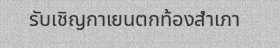

In [ ]:
from PIL import Image
import random

# اختر مسار صورة عشوائية من تلك التي تم توليدها
# سنقرأ من ملف CSV لنضمن أننا نختار صورة حقيقية تم توليدها
import csv
import os
import config

with open(config.TRAIN_LABELS_CSV, encoding="utf-8") as f:
    rows = list(csv.reader(f))

if rows:
    random_row = random.choice(rows)
    image_path_in_csv = random_row[0]
    true_text = random_row[1]

    full_image_path = os.path.join(config.IMAGES_ROOT_DIR, image_path_in_csv)

    print(f"الصورة المختارة: {full_image_path}")
    print(f"النص الحقيقي: {true_text}")

    img = Image.open(full_image_path)
    display(img)
else:
    print("لم يتم العثور على أي بيانات في ملف train_labels.csv لعرضها.")

In [ ]:
import os
import csv
import config

with open(config.TRAIN_LABELS_CSV, encoding="utf-8") as f:
    rows = list(csv.reader(f))

assert len(rows) > 0, f"ملف {config.TRAIN_LABELS_CSV} فارغ أو غير موجود"

for i, row in enumerate(rows[:5]):
    full_path = os.path.join(config.IMAGES_ROOT_DIR, row[0])
    assert os.path.exists(full_path), (
        f"مفقود: {full_path}\n"
        f"تحقق من config.IMAGES_ROOT_DIR (الحالي: \'{config.IMAGES_ROOT_DIR}\') "
        f"مقابل المسار الفعلي المخزَّن في CSV: \'{row[0]}\'"
    )

print(f"✅ تم فحص {min(5, len(rows))} من أصل {len(rows)} عيّنة — كل المسارات سليمة.")

✅ تم فحص 5 من أصل 190000 عيّنة — كل المسارات سليمة.


In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

import config
from dataset import ThaiOCRDataset, thai_collate_fn
from model import ThaiCRNN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("الجهاز المستخدم:", device)

CHECKPOINTS_DIR = config.CHECKPOINTS_DIR   # أو DRIVE_CHECKPOINT_DIR إذا فعّلت Google Drive
os.makedirs(CHECKPOINTS_DIR, exist_ok=True)

train_dataset = ThaiOCRDataset(config.TRAIN_LABELS_CSV, config.IMAGES_ROOT_DIR)
train_loader = DataLoader(
    train_dataset,
    batch_size=config.BATCH_SIZE,
    shuffle=True,
    num_workers=config.CPU_WORKERS,
    collate_fn=thai_collate_fn,
)

model = ThaiCRNN().to(device)
criterion = nn.CTCLoss(blank=config.BLANK_LABEL, reduction="mean", zero_infinity=True)
optimizer = optim.Adam(model.parameters(), lr=config.LEARNING_RATE)

EPOCHS_TO_RUN = 5   # ابدأ بعدد صغير للتأكد أن كل شيء يعمل، ثم ارفعه لـ config.EPOCHS

global_step = 0
for epoch in range(1, EPOCHS_TO_RUN + 1):
    model.train()
    epoch_loss = 0.0
    progress = tqdm(train_loader, desc=f"الحقبة {epoch}/{EPOCHS_TO_RUN}")

    for images, targets, target_lengths in progress:
        images = images.to(device)
        targets = targets.to(device)
        target_lengths = target_lengths.to(device)

        batch_size = images.size(0)
        log_probs = model(images)
        T = log_probs.size(0)

        input_lengths = torch.full((batch_size,), T, dtype=torch.long, device=device)

        loss = criterion(log_probs, targets, input_lengths, target_lengths)

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5)
        optimizer.step()

        epoch_loss += loss.item()
        global_step += 1
        progress.set_postfix(loss=loss.item())

        if global_step % config.SAVE_INTERVAL == 0:
            ckpt_path = os.path.join(CHECKPOINTS_DIR, f"thai_crnn_step{global_step}.pt")
            torch.save(model.state_dict(), ckpt_path)

    avg_loss = epoch_loss / max(len(train_loader), 1)
    print(f"--- الحقبة {epoch}  |  متوسط CTC Loss: {avg_loss:.4f} ---")

final_path = os.path.join(CHECKPOINTS_DIR, "thai_crnn_final.pt")
torch.save(model.state_dict(), final_path)
print("اكتمل التدريب. تم الحفظ في:", final_path)

الجهاز المستخدم: cuda


الحقبة 1/5:   0%|          | 0/5938 [00:00<?, ?it/s]

تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
--- الحقبة 1  |  متوسط CTC Loss: 1.3338 ---


الحقبة 2/5:   0%|          | 0/5938 [00:00<?, ?it/s]

تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
--- الحقبة 2  |  متوسط CTC Loss: 0.1661 ---


...

تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
--- الحقبة 3  |  متوسط CTC Loss: 0.1367 ---


الحقبة 4/5:   0%|          | 0/5938 [00:00<?, ?it/s]

تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
--- الحقبة 4  |  متوسط CTC Loss: 0.1260 ---


الحقبة 5/5:   0%|          | 0/5938 [00:00<?, ?it/s]

تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
تحذير: الرمز '…' (U+2026) غير موجود في الأبجدية، سيُتجاهل.
--- الحقبة 5  |  متوسط CTC Loss: 0.1205 ---
اكتمل التدريب. تم الحفظ في: checkpoints/thai_crnn_final.pt


## 6.6) تحميل وتجهيز الخطوط التايلاندية

نظرًا لأن خلايا إنشاء البيانات التجريبية أظهرت تحذيرًا بخصوص عدم وجود خطوط، سنقوم الآن بإنشاء مجلد `fonts/` داخل مجلد المشروع وتنزيل بعض الخطوط التايلاندية الشائعة مثل Noto Sans Thai و Sarabun. سيتم تحديث `generate_thai_data.py` تلقائيًا لاستخدام هذه الخطوط.

## 8) الاستدلال (تجربة النموذج على صورة)

يحمّل آخر نقطة تحقق محفوظة، ويطبّق `greedy_decode` على صورة من مجموعة البيانات
لعرض النتيجة، مع حساب Character Error Rate (CER) إن كانت التسمية الحقيقية معروفة.

In [ ]:
import torch
from model import ThaiCRNN
from ctc_decoder import greedy_decode, character_error_rate
from dataset import ThaiOCRDataset
import config

model.eval()
sample_dataset = ThaiOCRDataset(config.TRAIN_LABELS_CSV, config.IMAGES_ROOT_DIR)

with torch.no_grad():
    for i in range(3):
        image, target_indices, target_len = sample_dataset[i]
        image_batch = image.unsqueeze(0).to(device)
        log_probs = model(image_batch)
        pred_text = greedy_decode(log_probs)[0]

        true_text = sample_dataset.samples[i][1]
        cer = character_error_rate(pred_text, true_text)

        print(f"الحقيقي: {true_text}   |   المتوقَّع: {pred_text}   |   CER: {cer:.2%}")

الحقيقي: เฉทไปสวรรค์กรณีจำเป็น   |   المتوقَّع: เฉทไปสวรรค์กรณีจำเป็น   |   CER: 0.00%
الحقيقي: ช๊อกโกแลตการส่าย   |   المتوقَّع: ช๊อกโกแลตการส่าย   |   CER: 0.00%
الحقيقي: จ่อยไม่ต้องการ   |   المتوقَّع: จ่อยไม่ต้องการ   |   CER: 0.00%


## ملاحظات ختامية حول مشاكل المكتبات الشائعة في Colab

1. **لا تُعِد تثبيت `torch`/`torchvision` يدوياً** إلا إذا كنت تعرف بالضبط إصدار
   CUDA المطلوب — النسخة المثبَّتة مسبقاً في Colab متوافقة دائماً مع الـ GPU المخصَّص لك.
2. **إذا ظهر خطأ `ImportError` بعد تثبيت `pythainlp`**: نفّذ
   `Runtime > Restart session` (ليس `Restart runtime and run all` لتفادي إعادة تحميل كل شيء من الصفر
   دون داعٍ)، ثم أعد تشغيل الخلايا بدءاً من خلية `import pythainlp`.
3. **لا تستخدم `python-Levenshtein` أو `jiwer` لحساب CER** إلا إذا احتجت لذلك فعلاً؛
   كتبنا دالة `character_error_rate` يدوياً في `ctc_decoder.py` لتفادي مشاكل تثبيت
   حزم تعتمد على تصريف C (C-extension compilation) قد تفشل بصمت في بعض بيئات Colab.
4. **إذا نفدت ذاكرة GPU (`CUDA out of memory`)**: قلّل `config.BATCH_SIZE` (جرّب 16 أو 8)
   بدلاً من تغيير بنية النموذج.
5. عند تشغيل خلية `%%writefile` أكثر من مرة بعد تعديل الكود، **الخلية التالية
   (`importlib.reload`) ضرورية** لضمان أن بايثون لا يستخدم نسخة قديمة مخبأة من الوحدة (module cache).
6. **حول `AssertionError: can only test a child process`**: قد يظهر هذا التحذير
   بين الحقب إذا رفعت `config.CPU_WORKERS` لأكثر من 0 — وهو خلل معروف في تفاعل
   `ipykernel`/Colab مع تنظيف عمليات `DataLoader` الفرعية، **وغير مؤثر على صحة
   التدريب** (يظهر داخل `Exception ignored in __del__`، أي أثناء تنظيف الذاكرة
   وليس أثناء التنفيذ الفعلي). تم ضبط `CPU_WORKERS = 0` افتراضياً في هذا الدفتر
   لتفادي ظهوره نهائياً؛ لا ترفعه إلا إذا كانت بياناتك كبيرة جداً وأصبح تحميل
   الصور فعلياً عنق زجاجة (bottleneck) في سرعة التدريب.
7. **تحقق دائماً من مسار `config.IMAGES_ROOT_DIR` مقابل الصيغة الفعلية للمسارات
   المخزَّنة في ملف CSV** قبل التدريب — أشيع خطأ `FileNotFoundError` في هذا
   المشروع سببه تكرار جزء من المسار (مثل `data/images/images/...`) بسبب عدم
   تطابق الاثنين. خلية التحقق في القسم (6.5) أعلاه مصممة خصيصاً لالتقاط هذا مبكراً.
